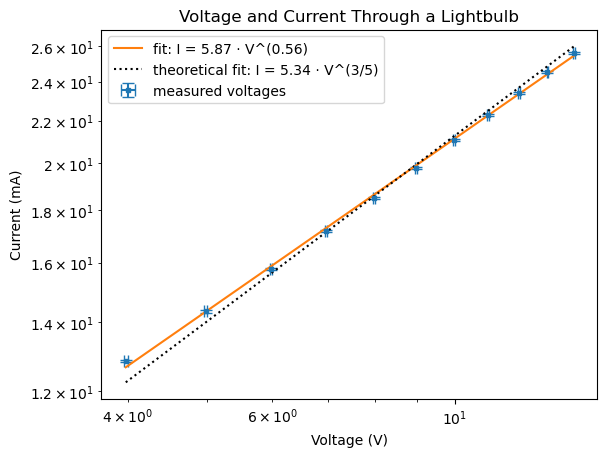

Fit parameter a: 5.8698 ± 0.0231
Exponent b: 0.5564 ± 0.0018


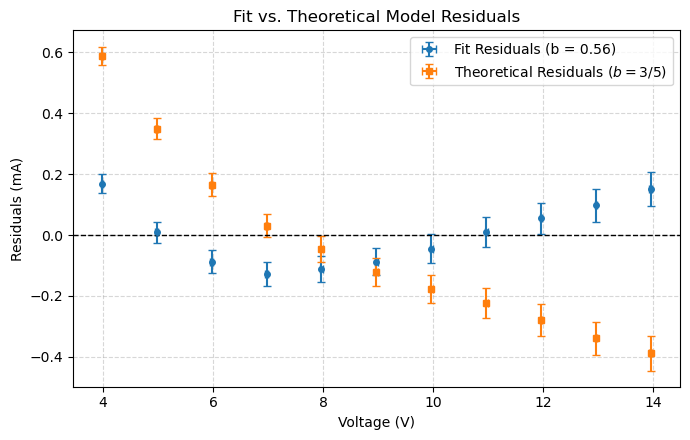

Empirical fit reduced chi-squared: 7.696
Theoretical fit reduced chi-squared: 64.580


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#data
voltage, unc_v, current, unc_i = np.loadtxt("PHY244 lightbulb data - Sheet1.csv", skiprows = 1, delimiter = ',', comments = '#', unpack = True)
#unc: uncertainty

#linear model
def power_law_model(V,a,b):
    return a*(V**b)

#fit model to data
popt, pcov = curve_fit(power_law_model,
                    voltage,
                    current,
                    sigma = unc_i,
                    absolute_sigma = True,
                    p0=[0.5, 0.5])

pstd = (np.sqrt(np.diag(pcov)))

#plot data
plt.errorbar(voltage, current, xerr=unc_v, yerr=unc_i, ls='', marker='s', markersize=3, capsize=4, capthick=1, label="measured voltages")

#plot curve fit
v_line = np.linspace(np.min(voltage), np.max(voltage), 100)
plt.plot(v_line, power_law_model(v_line, *popt), label=f"fit: I = {popt[0]:.2f} · V^({popt[1]:.2f})")

#theoretical fit
def theo_model(V, a_theo):
    return a_theo * (V ** (3/5))
popt_theo, pcov_theo = curve_fit(theo_model, voltage, current, sigma=unc_i, absolute_sigma=True, p0=[0.5])
a_theo = popt_theo[0]
plt.plot(v_line, theo_model(v_line, a_theo), 'k:', label=f"theoretical fit: I = {a_theo:.2f} · V^(3/5)")

#decorate the plot
plt.xlabel("Voltage (V)")
plt.ylabel("Current (mA)")
plt.title("Voltage and Current Through a Lightbulb")
plt.legend()
plt.loglog()
plt.show()

print(f"Fit parameter a: {popt[0]:.4f} ± {pstd[0]:.4f}")
print(f"Exponent b: {popt[1]:.4f} ± {pstd[1]:.4f}")

#residual plots
fit_residuals = current - power_law_model(voltage, *popt)
theo_residuals = current - theo_model(voltage, a_theo)

plt.figure(figsize=(7, 4.5))
plt.errorbar(voltage, fit_residuals, yerr=unc_i, xerr=unc_v, ls='', marker='o', markersize=4, capsize=3, label=f"Fit Residuals (b = {popt[1]:.2f})")
plt.errorbar(voltage, theo_residuals, yerr=unc_i, xerr=unc_v, ls='', marker='s', markersize=4, capsize=3, label=r"Theoretical Residuals ($b = 3/5$)")
plt.axhline(0, color='black', linestyle='--', linewidth=1)

plt.xlabel("Voltage (V)")
plt.ylabel("Residuals (mA)")
plt.title("Fit vs. Theoretical Model Residuals")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

#chi squared
def chi_squared(data, model_values, uncertainty):
    difference = data - model_values
    diff_unc = difference / uncertainty
    diff_squared = diff_unc**2
    return np.sum(diff_squared)

def reduced_chi_squared(data, model_values, uncertainty, num_params=2):
    dof = len(data) - num_params
    return chi_squared(data, model_values, uncertainty) / dof

fit_model_data = power_law_model(voltage, *popt)
red_chi2_fit = reduced_chi_squared(current, fit_model_data, unc_i, num_params=2)

theo_model_data = theo_model(voltage, a_theo)
red_chi2_theo = reduced_chi_squared(current, theo_model_data, unc_i, num_params=1)

print(f"Empirical fit reduced chi-squared: {red_chi2_fit:.3f}")
print(f"Theoretical fit reduced chi-squared: {red_chi2_theo:.3f}")